# EDA : Exploratory Data Analysis is the process where we explore data statistically so that we get to know what all are the information inside dataset

1) In this project we will explore data of patients in a hospital and create analytical dashboard to show required information on website
2) to start this project create database file and hospital_data.db file should exist in current project folder

# hospital_data.db is the file where database ,dataset will be stored

# create_hospital_db.sql is the file by using which we will create a database inside hospital _data.db

go to cmd and type pip install sqlite3

# EDA

In [1]:
import sqlite3 as sql

In [2]:
conn = sql.connect('hospital_data.db') # connecting database file for storage
cursor = conn.cursor() # creating cursor to execute sql querries by using python
with open('create_hospital_db.sql','r',encoding='utf-8-sig') as file:
    queries = file.read() # reading sql querries to create database inside hospital_data.db

In [3]:
for i in queries.split(';'):
    if not(i.startswith('--')):
        cursor.executescript(i) # executing sql and storing data in hospital_data.db
        conn.commit() # making permanent changes

IntegrityError: UNIQUE constraint failed: payers.Id

In [ ]:
# queries

In [4]:
import pandas as pd
pd.read_sql('select * from payers;',conn)

,Id,NAME,ADDRESS,CITY,STATE_HEADQUARTERED,ZIP,PHONE
0,b3221cfc-24fb-339e-823d-bc4136cbc4ed,Dual Eligible,7500 Security Blvd,Baltimore,MD,21244,1-877-267-2323
1,7caa7254-5050-3b5e-9eae-bd5ea30e809c,Medicare,7500 Security Blvd,Baltimore,MD,21244,1-800-633-4227
2,7c4411ce-02f1-39b5-b9ec-dfbea9ad3c1a,Medicaid,7500 Security Blvd,Baltimore,MD,21244,1-877-267-2323
3,d47b3510-2895-3b70-9897-342d681c769d,Humana,500 West Main St,Louisville,KY,40018,1-844-330-7799
4,6e2f1a2d-27bd-3701-8d08-dae202c58632,Blue Cross Blue Shield,Michigan Plaza,Chicago,IL,60007,1-800-262-2583
5,5059a55e-5d6e-34d1-b6cb-d83d16e57bcf,UnitedHealthcare,9800 Healthcare Lane,Minnetonka,MN,55436,1-888-545-5205
6,4d71f845-a6a9-3c39-b242-14d25ef86a8d,Aetna,151 Farmington Ave,Hartford,CT,06156,1-800-872-3862
7,047f6ec3-6215-35eb-9608-f9dda363a44c,Cigna Health,900 Cottage Grove Rd,Bloomfield,CT,06002,1-800-997-1654
8,42c4fca7-f8a9-3cd1-982a-dd9751bf3e2a,Anthem,220 Virginia Ave,Indianapolis,IN,46204,1-800-331-1476
9,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,NO_INSURANCE,NaN,NaN,NaN,NaN,NaN


In [5]:
import pandas as pd
pd.read_sql('select * from sqlite_master;',conn)

,type,name,tbl_name,rootpage,sql
0,table,payers,payers,2,CREATE TABLE payers (\n Id CHAR(36) PRIMARY...
1,index,sqlite_autoindex_payers_1,payers,3,NaN
2,table,patients,patients,4,CREATE TABLE patients (\n Id CHAR(36) PRIMA...
3,index,sqlite_autoindex_patients_1,patients,5,NaN
4,table,procedures,procedures,72,CREATE TABLE procedures (\n START TIMESTAMP...
5,table,encounters,encounters,2220,CREATE TABLE encounters (\n Id CHAR(36) PRIMA...
6,index,sqlite_autoindex_encounters_1,encounters,2221,NaN


In [6]:
pay=pd.read_sql('select * from payers;',conn)
pat=pd.read_sql('select * from patients;',conn)
enc=pd.read_sql('select * from encounters;',conn)

In [7]:
dfs=[('payers',pay),('patients',pat),('Encounter',enc)]

In [8]:
for N,i in dfs:
    print(N,'=>',i.columns) # please refer data dictionary for details description of column name

payers => Index(['Id', 'NAME', 'ADDRESS', 'CITY', 'STATE_HEADQUARTERED', 'ZIP', 'PHONE'], dtype='str')
patients => Index(['Id', 'BIRTHDATE', 'DEATHDATE', 'PREFIX', 'FIRST', 'LAST', 'SUFFIX',
       'MAIDEN', 'MARITAL', 'RACE', 'ETHNICITY', 'GENDER', 'BIRTHPLACE',
       'ADDRESS', 'CITY', 'STATE', 'COUNTY', 'ZIP', 'LAT', 'LON'],
      dtype='str')
Encounter => Index(['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PAYER',
       'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST',
       'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE',
       'REASONDESCRIPTION'],
      dtype='str')


In [9]:
for N,df in dfs:
    print('Statical Info for Numeric Data')
    print(N)
    print(N,df.describe().T)
    print('Statistical Info for Categorical Data')
    print(N)
    print(N,df.describe(include='object').T)

Statical Info for Numeric Data
payers


C:\Users\Lalit\AppData\Local\Temp\ipykernel_10308\3732357613.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(N,df.describe(include='object').T)


payers                     count unique                                   top freq
Id                     10     10  b3221cfc-24fb-339e-823d-bc4136cbc4ed    1
NAME                   10     10                         Dual Eligible    1
ADDRESS                 9      7                    7500 Security Blvd    3
CITY                    9      7                             Baltimore    3
STATE_HEADQUARTERED     9      6                                    MD    3
ZIP                     9      7                                 21244    3
PHONE                   9      8                        1-877-267-2323    2
Statistical Info for Categorical Data
payers
payers                     count unique                                   top freq
Id                     10     10  b3221cfc-24fb-339e-823d-bc4136cbc4ed    1
NAME                   10     10                         Dual Eligible    1
ADDRESS                 9      7                    7500 Security Blvd    3
CITY                    9    

C:\Users\Lalit\AppData\Local\Temp\ipykernel_10308\3732357613.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(N,df.describe(include='object').T)
C:\Users\Lalit\AppData\Local\Temp\ipykernel_10308\3732357613.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-st

Encounter                    count unique                                          top  \
Id                 27891  27891         32c84703-2481-49cd-d571-3899d5820253   
START              27891  27541                          2016-12-08 10:00:40   
STOP               27891  27765                          2016-12-08 10:15:40   
PATIENT            27891    974         1712d26d-822d-1e3a-2267-0a9dba31d7c8   
ORGANIZATION       27891      1         d78e84ec-30aa-3bba-a33a-f29a3a454662   
PAYER              27891     10         7caa7254-5050-3b5e-9eae-bd5ea30e809c   
ENCOUNTERCLASS     27891      6                                   ambulatory   
CODE               27891     45                                    185347001   
DESCRIPTION        27891     53            Encounter for problem (procedure)   
REASONCODE          8350     73                                     88805009   
REASONDESCRIPTION   8350     73  Chronic congestive heart failure (disorder)   

                    freq  
Id

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

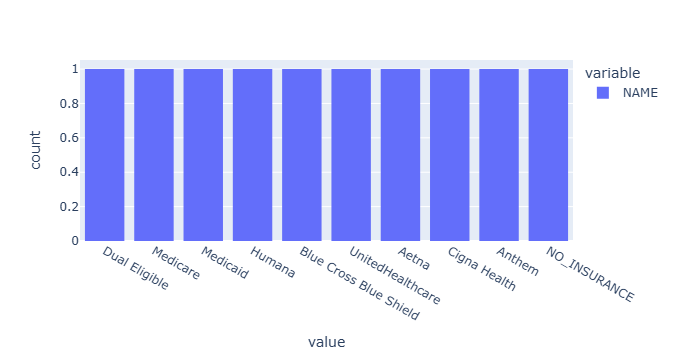

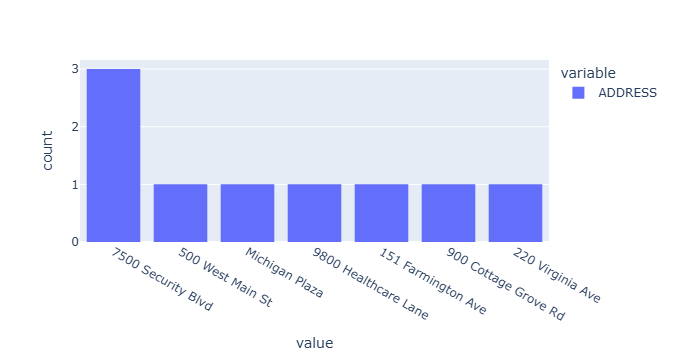

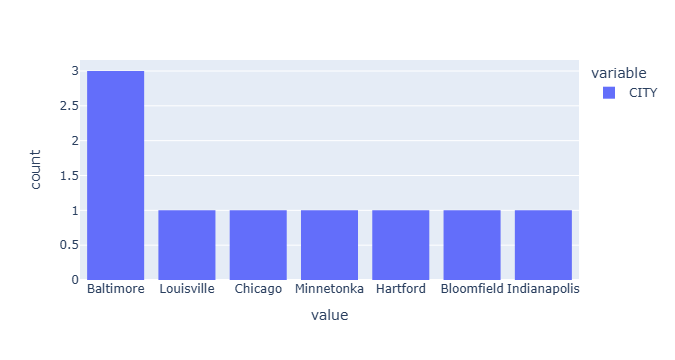

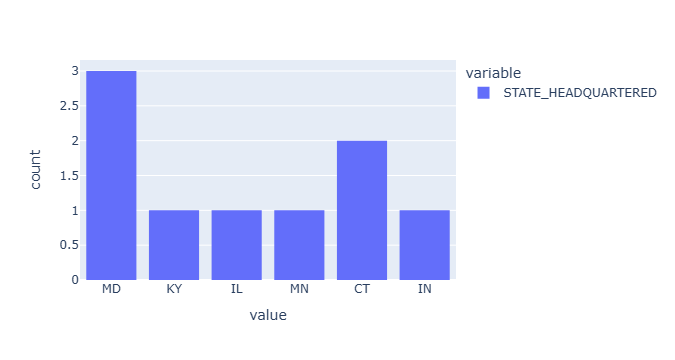

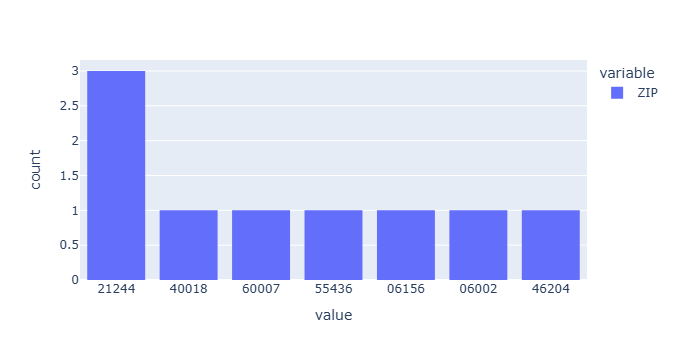

...

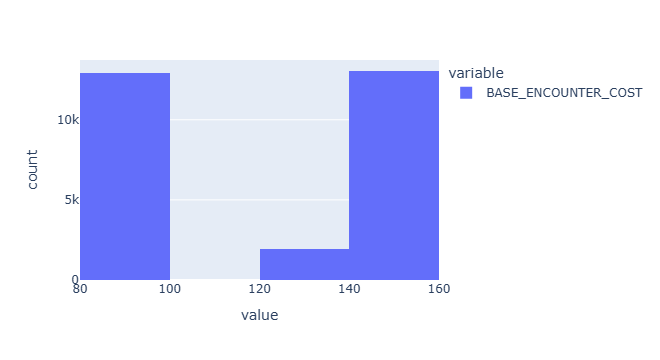

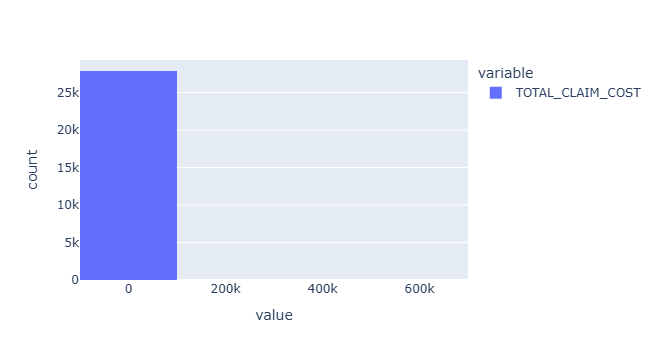

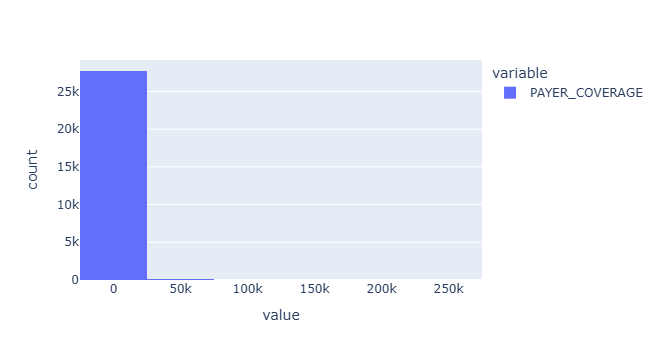

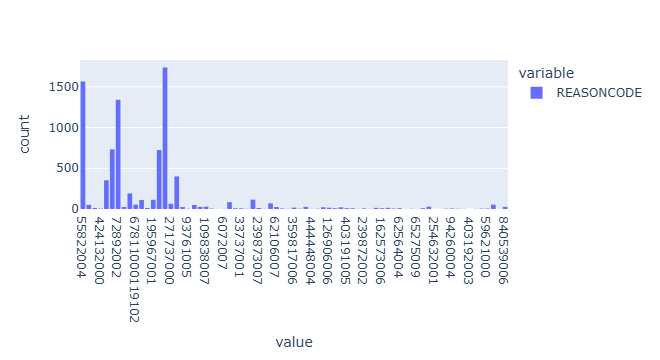

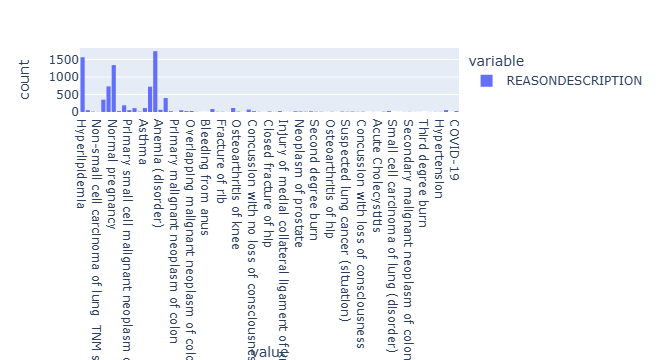

In [11]:
for N,df in dfs:
    for col in df.columns:
        if df[col].dtypes!='object' and 'id' not in col.lower():
            fig=px.histogram(df[col],nbins=5)
            fig.show()
        elif df[col].dtypes=='object' and 'id' not in col.lower():
            fig=px.histogram(df[col],text_auto=True)
            fig.show()

In [12]:
dfs[0][1].dtypes

Id                     str
NAME                   str
ADDRESS                str
CITY                   str
STATE_HEADQUARTERED    str
ZIP                    str
PHONE                  str
dtype: object

In [13]:
dfs[2][1].dtypes

Id                         str
START                      str
STOP                       str
PATIENT                    str
ORGANIZATION               str
PAYER                      str
ENCOUNTERCLASS             str
CODE                       str
DESCRIPTION                str
BASE_ENCOUNTER_COST    float64
TOTAL_CLAIM_COST       float64
PAYER_COVERAGE         float64
REASONCODE                 str
REASONDESCRIPTION          str
dtype: object

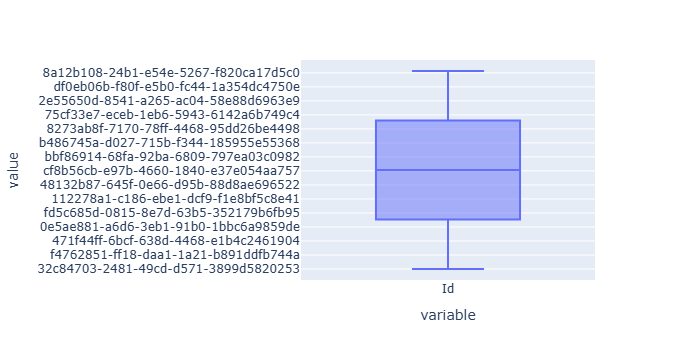

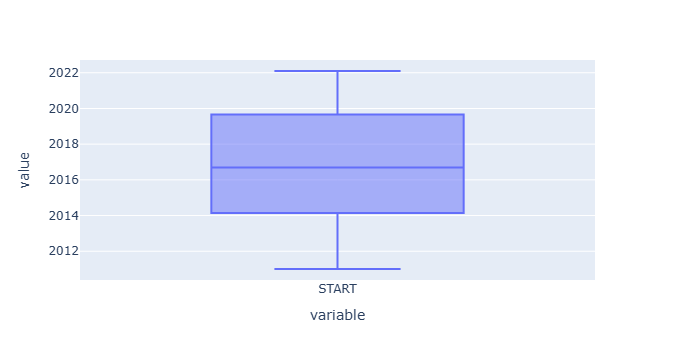

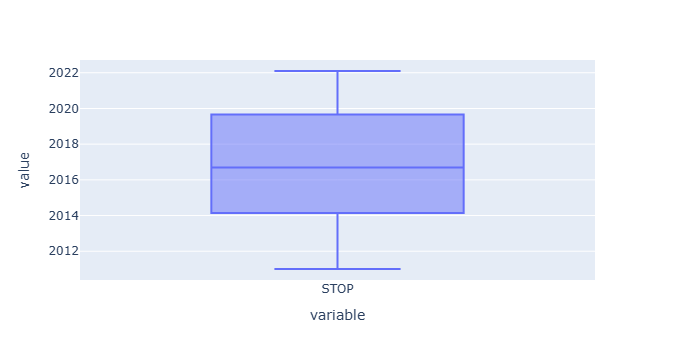

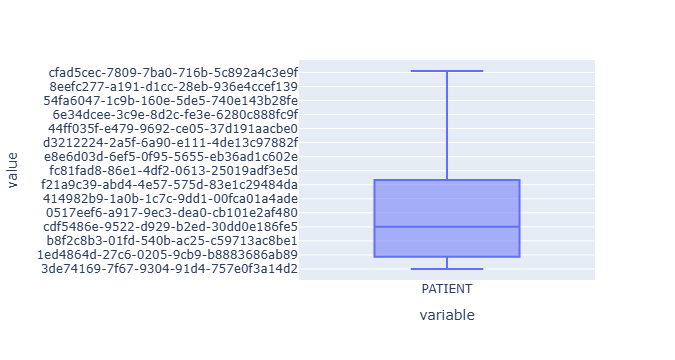

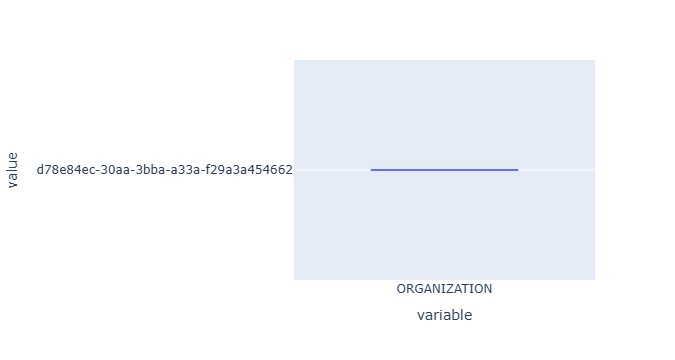

...

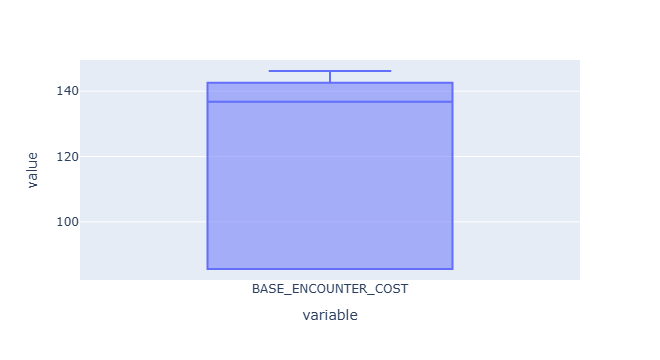

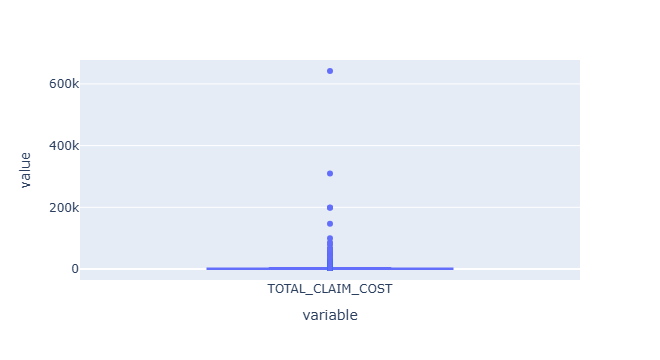

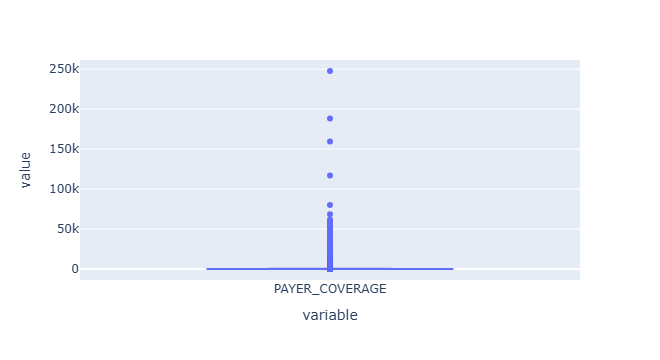

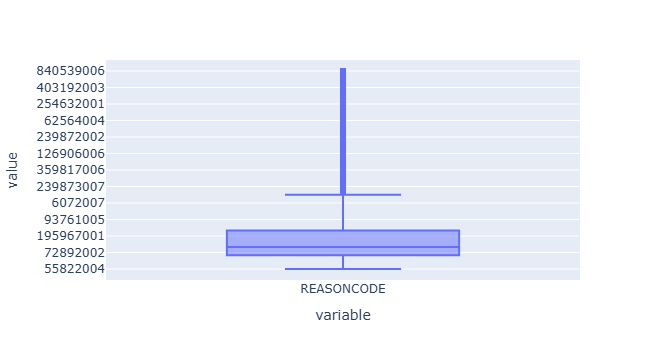

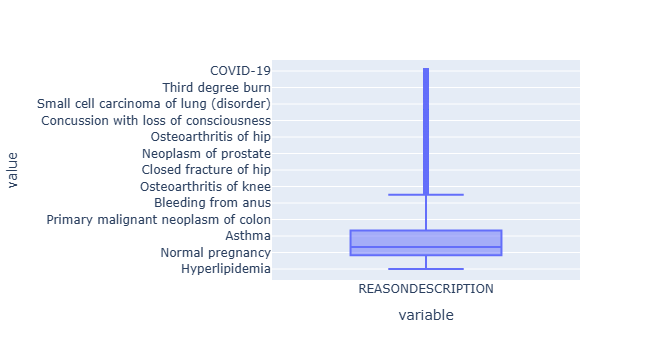

In [14]:
for i in dfs[2][1].columns:
    if dfs[2][1][i].dtypes!='object':
        fig=px.box(dfs[2][1][i])
        fig.show()

In [15]:
dfs[2][1].columns

Index(['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PAYER',
       'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST',
       'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE',
       'REASONDESCRIPTION'],
      dtype='str')

In [16]:
Paydf = dfs[2][1][['BASE_ENCOUNTER_COST',
       'TOTAL_CLAIM_COST', 'PAYER_COVERAGE']]

In [17]:
Paydf = pd.melt(Paydf,value_vars=['BASE_ENCOUNTER_COST',
       'TOTAL_CLAIM_COST', 'PAYER_COVERAGE']).rename(columns = {'variable': 'Cost_Category','value': 'cost'})

In [18]:
Paydf=Paydf.groupby('Cost_Category').agg({'cost':'sum'}).reset_index().sort_values('cost',ascending=False)

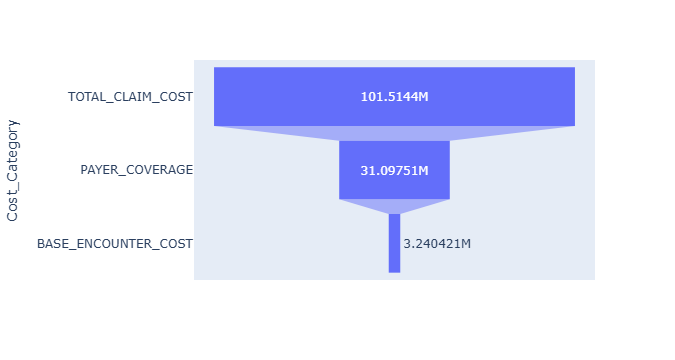

In [19]:
px.funnel(Paydf,x='cost',y='Cost_Category')

In [20]:
dfs[2][1].describe().T

,count,mean,std,min,25%,50%,75%,max
BASE_ENCOUNTER_COST,27891.0,116.181614,28.410082,85.55,85.55,136.80,142.58,146.18
TOTAL_CLAIM_COST,27891.0,3639.682174,9205.595748,0.00,142.58,278.58,1412.53,641882.70
PAYER_COVERAGE,27891.0,1114.965652,4768.615576,0.00,0.00,28.44,155.77,247751.42


In [21]:
dfs[0][1].describe(include='object').T

C:\Users\Lalit\AppData\Local\Temp\ipykernel_10308\2173755130.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  dfs[0][1].describe(include='object').T


,count,unique,top,freq
Id,10,10,b3221cfc-24fb-339e-823d-bc4136cbc4ed,1
NAME,10,10,Dual Eligible,1
ADDRESS,9,7,7500 Security Blvd,3
CITY,9,7,Baltimore,3
STATE_HEADQUARTERED,9,6,MD,3
ZIP,9,7,21244,3
PHONE,9,8,1-877-267-2323,2


In [22]:
dfs[1][1].describe(include='object').T

C:\Users\Lalit\AppData\Local\Temp\ipykernel_10308\3861122336.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  dfs[1][1].describe(include='object').T


,count,unique,top,freq
Id,973,973,5605b66b-e92d-c16c-1b83-b8bf7040d51f,1
BIRTHDATE,973,879,1929-01-28,4
DEATHDATE,0,0,NaN,NaN
PREFIX,973,3,Mr.,494
FIRST,973,841,Armando772,3
LAST,973,498,Heaney114,6
SUFFIX,0,0,NaN,NaN
MAIDEN,973,280,,588
MARITAL,973,3,M,783
RACE,973,6,white,679


In [23]:
dfs[2][1].describe(include='object').T

C:\Users\Lalit\AppData\Local\Temp\ipykernel_10308\2992531475.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  dfs[2][1].describe(include='object').T


,count,unique,top,freq
Id,27891,27891,32c84703-2481-49cd-d571-3899d5820253,1
START,27891,27541,2016-12-08 10:00:40,3
STOP,27891,27765,2016-12-08 10:15:40,3
PATIENT,27891,974,1712d26d-822d-1e3a-2267-0a9dba31d7c8,1381
ORGANIZATION,27891,1,d78e84ec-30aa-3bba-a33a-f29a3a454662,27891
PAYER,27891,10,7caa7254-5050-3b5e-9eae-bd5ea30e809c,11371
ENCOUNTERCLASS,27891,6,ambulatory,12537
CODE,27891,45,185347001,5261
DESCRIPTION,27891,53,Encounter for problem (procedure),4308
REASONCODE,8350,73,88805009,1738


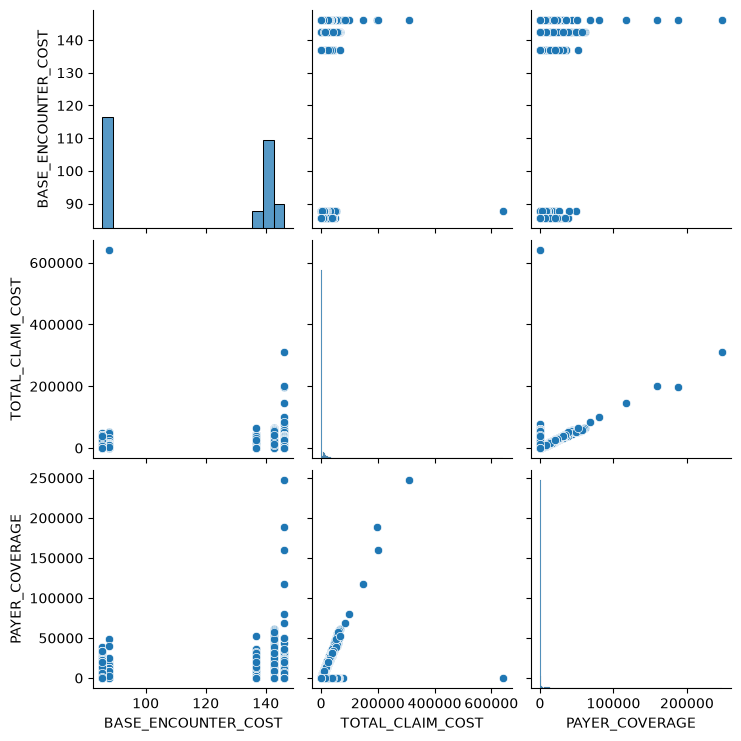

In [24]:
sns.pairplot(dfs[2][1])

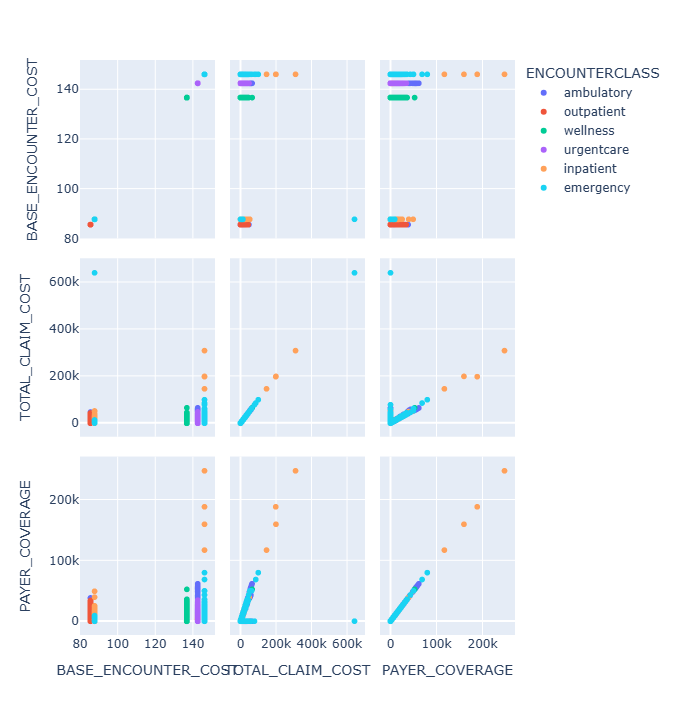

In [25]:
fig=px.scatter_matrix(dfs[2][1],dimensions=['BASE_ENCOUNTER_COST','TOTAL_CLAIM_COST','PAYER_COVERAGE'],color='ENCOUNTERCLASS')
fig.update_layout(width=1000,height=700)

# Dashboard Building

In [26]:
#Total Patients
dfs[1][1]['Id'].nunique()

973

In [64]:
# Total Insurance Payer
dfs[0][1]['Id'].nunique()

10

In [73]:
# Total Medical Procedures
dfs[2][1]['DESCRIPTION'].nunique()

53

In [71]:
# Total Claim Cost
'$'+str(round(dfs[2][1]['TOTAL_CLAIM_COST'].sum()/1000000)) + 'M'

'$102M'

In [76]:
# payer coverage
'$'+str(round(dfs[2][1]['PAYER_COVERAGE'].sum()/1000000))+'M'

'$31M'

In [77]:
# Patient responsebility
'$'+str(round(dfs[2][1]['BASE_ENCOUNTER_COST'].sum()/1000000))+'M'

'$3M'

In [27]:
dfs[2][1]['START']=pd.to_datetime(dfs[2][1]['START'])
dfs[2][1]['STOP']=pd.to_datetime(dfs[2][1]['STOP'])

In [28]:
Time_wise_patients = dfs[2][1].groupby(
    [dfs[2][1]['START'].dt.year,dfs[2][1]['START'].dt.month]).agg(
    {'PATIENT':'nunique'})

In [29]:
This_month = Time_wise_patients.iloc[-2,-1]
Last_month = Time_wise_patients.iloc[-3,-1]
Growth =( (This_month / Last_month )-1 )*100
print(str(round(Growth))+'%')

-6%


In [30]:
# Total Encounters
dfs[2][1]['Id'].nunique()

27891

In [31]:
Time_wise_Encounters = dfs[2][1].groupby(
    [dfs[2][1]['START'].dt.year,dfs[2][1]['START'].dt.month]).agg(
    {'Id':'nunique'})
This_monthE = Time_wise_patients.iloc[-2,-1]
Last_monthE = Time_wise_patients.iloc[-3,-1]
GrowthE =( (This_month / Last_month )-1 )*100
print(str(round(GrowthE))+'%')

-6%


In [32]:
# Total insurance Companies
print('Total Insurance companies :' , len(dfs[0][1]['NAME'].unique())-1)

Total Insurance companies : 9


In [33]:
dfs[1][1].head(1)

,Id,BIRTHDATE,DEATHDATE,PREFIX,FIRST,LAST,SUFFIX,MAIDEN,MARITAL,RACE,ETHNICITY,GENDER,BIRTHPLACE,ADDRESS,CITY,STATE,COUNTY,ZIP,LAT,LON
0,5605b66b-e92d-c16c-1b83-b8bf7040d51f,1977-03-19,None,Mrs.,Nikita578,Erdman779,None,Leannon79,M,white,nonhispanic,F,Wakefield Massachusetts US,510 Little Station Unit 69,Quincy,Massachusetts,Norfolk County,02186,42.290937,-70.975503


In [34]:
BD = pd.to_datetime(dfs[1][1]['BIRTHDATE'])

In [35]:
import datetime as dt

In [36]:
AGE = (dt.datetime.now().year -BD.dt.year).astype('int8')

In [37]:
AGE

0       49
1       86
2       68
3       98
4       98
      ... 
968     84
969    102
970     86
971     83
972     85
Name: BIRTHDATE, Length: 973, dtype: int8

In [38]:
dt.datetime.now() .year

2026

In [39]:
print('Average Age of a Patient :', round(AGE.mean(),0))

Average Age of a Patient : 74.0


In [40]:
round((dfs[1][1]['GENDER'].value_counts()/(494+479))*100,0)

GENDER
M    51.0
F    49.0
Name: count, dtype: float64

In [41]:
round((dfs[1][1]['GENDER'].value_counts()/(494+479))*100,0).astype(str).str[:2]+'%'

GENDER
M    51%
F    49%
Name: count, dtype: str

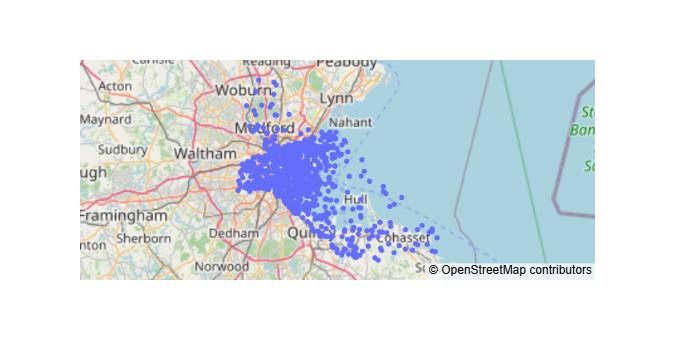

In [42]:
px.scatter_map(dfs[1][1],lat='LAT',lon='LON',hover_name='STATE',map_style='open-street-map')

In [43]:
years = [i[0] for i in Time_wise_Encounters.index] # extraction of years from index
month = [i[1] for i in Time_wise_Encounters.index] # extraction of month from index

In [44]:
Time_wise_Encounters['year']=years # creating new column for year
Time_wise_Encounters['month']=month # creating new column for month

In [45]:
Time_wise_Encounters=Time_wise_Encounters.reset_index(drop=True) # dropping index of time wise encounters

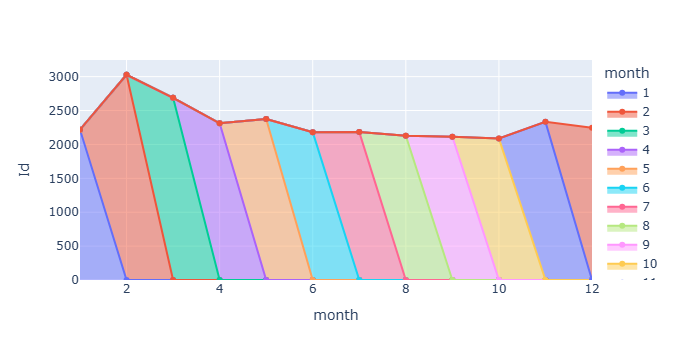

In [46]:
ME = Time_wise_Encounters.groupby('month').agg({'Id' : 'sum'}).reset_index() # grouping month wise data
px.area(ME,x='month',y='Id',markers='o',color='month') # creating line chart

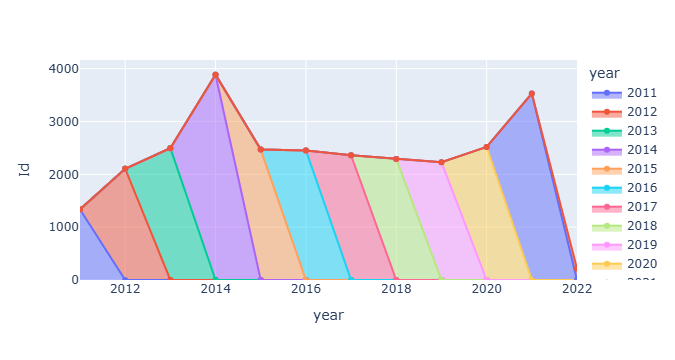

In [47]:
YE = Time_wise_Encounters.groupby('year').agg({'Id' : 'sum'}).reset_index() # grouping year wise data
px.area(YE,x='year',y='Id',markers='o',color='year') # creating line chart

In [48]:
from datetime import datetime as dt  # getting function for current date

dfs[1][1]['Age']=dt.now().year - pd.to_datetime(dfs[1][1]['BIRTHDATE']).dt.year # calculating age as per current date

In [49]:
dfs[1][1]['Age_bin'] = pd.cut(dfs[1][1]['Age'],bins = 5 , labels=['35 to 49' , '49 to 63' , '63 to 76' , '76 to 90' , '90 to 104']) # creating bins for age

In [50]:
Age_wise_patients = dfs[1][1].groupby('Age_bin' , observed = True).agg({'Id' : 'nunique'}).reset_index() # total patients as per bin 

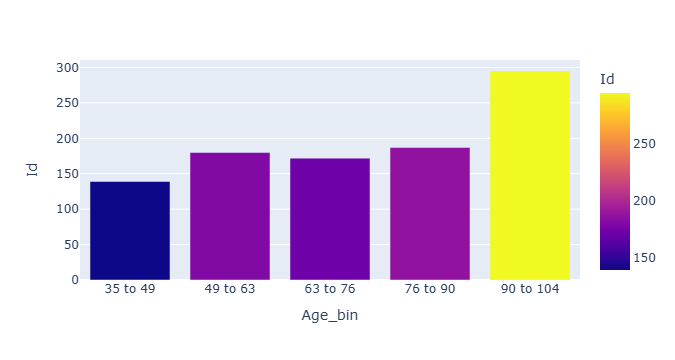

In [51]:
px.bar(Age_wise_patients , x = 'Age_bin' , y = 'Id' , color = 'Id')

In [52]:
GD = dfs[1][1]['GENDER'].value_counts().reset_index()

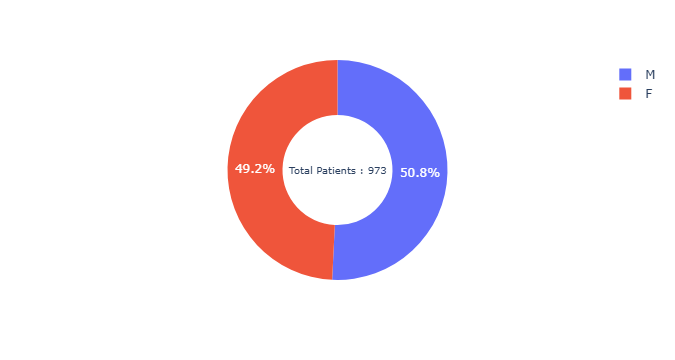

In [53]:
fig = px.pie( GD, names=GD['GENDER'],values=GD['count'], hole=0.5) 
fig.add_annotation(text = f'Total Patients : {dfs[1][1]['Id'].nunique()}', x=0.5 , y=0.5 , font_size=10 , showarrow = False)
fig.show()

In [54]:
payers=pd.read_csv('payers.csv')

In [55]:
payers.head(1)

,Id,NAME,ADDRESS,CITY,STATE_HEADQUARTERED,ZIP,PHONE
0,b3221cfc-24fb-339e-823d-bc4136cbc4ed,Dual Eligible,7500 Security Blvd,Baltimore,MD,21244.0,1-877-267-2323


In [56]:
payer=pd.merge(dfs[2][1],payers,left_on='PAYER',right_on='Id',how='inner')

In [57]:
Top_Payers=payer.groupby('NAME').agg({'PAYER_COVERAGE':'sum'}).sort_values('PAYER_COVERAGE').iloc[::,:].reset_index()

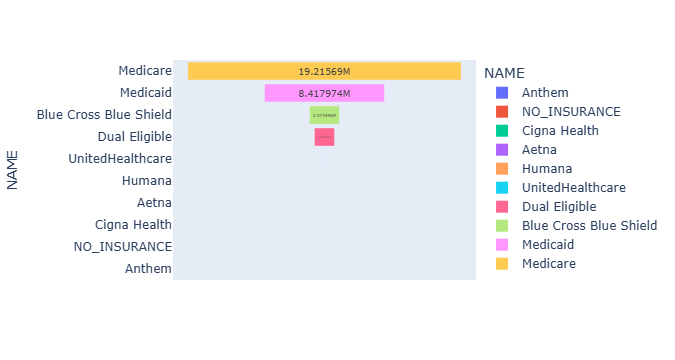

In [58]:
fig=px.funnel(Top_Payers,x='PAYER_COVERAGE',y='NAME',color='NAME')
fig.update_traces(textposition='inside',textfont_size=14)

In [59]:
dfs[2][1].head()

,Id,START,STOP,PATIENT,ORGANIZATION,PAYER,ENCOUNTERCLASS,CODE,DESCRIPTION,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE,REASONDESCRIPTION
0,32c84703-2481-49cd-d571-3899d5820253,2011-01-02 09:26:36,2011-01-02 12:58:36,3de74169-7f67-9304-91d4-757e0f3a14d2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,ambulatory,185347001,Encounter for problem (procedure),85.55,1018.02,0.00,NaN,NaN
1,c98059da-320a-c0a6-fced-c8815f3e3f39,2011-01-03 05:44:39,2011-01-03 06:01:42,d9ec2e44-32e9-9148-179a-1653348cc4e2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,outpatient,308335008,Patient encounter procedure,142.58,2619.36,0.00,NaN,NaN
2,4ad28a3a-2479-782b-f29c-d5b3f41a001e,2011-01-03 14:32:11,2011-01-03 14:47:11,73babadf-5b2b-fee7-189e-6f41ff213e01,d78e84ec-30aa-3bba-a33a-f29a3a454662,7caa7254-5050-3b5e-9eae-bd5ea30e809c,outpatient,185349003,Encounter for check up (procedure),85.55,461.59,305.27,NaN,NaN
3,c3f4da61-e4b4-21d5-587a-fbc89943bc19,2011-01-03 16:24:45,2011-01-03 16:39:45,3b46a0b7-0f34-9b9a-c319-ace4a1f58c0b,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,wellness,162673000,General examination of patient (procedure),136.80,1784.24,0.00,NaN,NaN
4,a9183b4f-2572-72ea-54c2-b3cd038b4be7,2011-01-03 17:36:53,2011-01-03 17:51:53,fa006887-d93c-d302-8b89-f3c25f88c0e1,d78e84ec-30aa-3bba-a33a-f29a3a454662,42c4fca7-f8a9-3cd1-982a-dd9751bf3e2a,ambulatory,390906007,Follow-up encounter,85.55,234.72,0.00,55822004,Hyperlipidemia


# Top Encounter Class

In [60]:
Top_Encounter=dfs[2][1].groupby('ENCOUNTERCLASS').agg(
    {'Id':'count'}).sort_values('Id').iloc[::,:].reset_index()

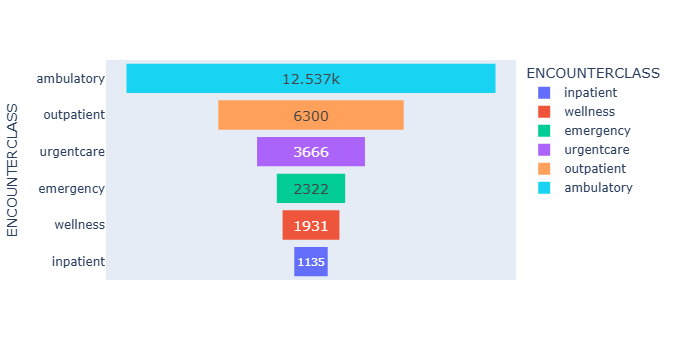

In [61]:
fig=px.funnel(Top_Encounter,x='Id', y='ENCOUNTERCLASS',color='ENCOUNTERCLASS')
fig.update_traces(textposition='inside',textfont_size=14)

In [62]:
Desc = dfs[2][1].groupby('DESCRIPTION').agg({'Id':'count'}).reset_index().sort_values('Id').tail(5)

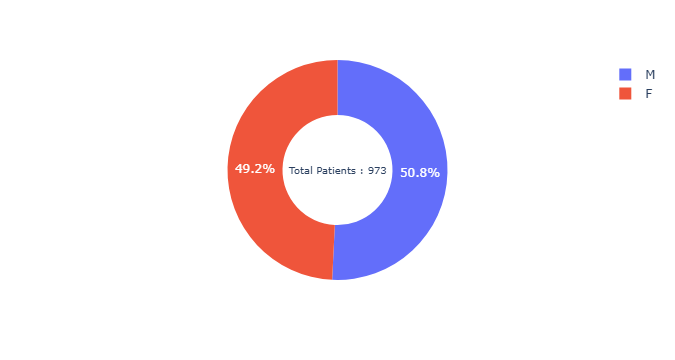

In [63]:
fig = px.pie( GD, names=GD['GENDER'],values=GD['count'], hole=0.5) 
fig.add_annotation(text = f'Total Patients : {dfs[1][1]['Id'].nunique()}', x=0.5 , y=0.5 , font_size=10 , showarrow = False)
fig.show()